# 10 · From storm rain rates to water volume

**Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.**

A team planning field checks near the Black River wants a storm rainfall total. The exercise uses four half-hour intervals and three invented portions of grid cells. Their footprints and rain rates describe a teaching basin, with no connection to a measured flood or a mapped catchment.

## Keep the rate, time and area together

The half-hourly IMERG V07 fields described by NASA use a 0.1° latitude–longitude grid. Read the product and variable metadata before converting a file. The exercise assumes interval-average rates in millimetres per hour. Products that already supply interval depth need no extra multiplication by time. [NASA IMERG V07 technical documentation](https://gpm.nasa.gov/resources/documents/imerg-v07-technical-documentation) · [NASA Earthdata, half-hour accumulation clarification](https://forum.earthdata.nasa.gov/viewtopic.php?t=6779)

Multiply rate $r_{ti}$ by interval length $\Delta t_t$ in hours to get depth in each cell $i$. Sum the depths over the storm. To get basin-average depth, weight each cell by the area $A_i$ **inside the basin**. Using the whole cell would count rainfall outside it. Convert the weighted sum to cubic metres:

$$
d_i=\sum_t r_{ti}\Delta t_t,\qquad
\bar d=\frac{\sum_i d_i A_i}{\sum_i A_i},\qquad
V=1000\sum_i d_i A_i.
$$

Here $d_i$ is in mm and $A_i$ is in km². The last factor follows from 0.001 m of depth multiplied by 1,000,000 m² of area.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Rows are half-hour intervals. Columns are grid-cell portions inside the basin.
rain_mm_h = np.array([
    [12.0, 4.0, 0.0],
    [20.0, 8.0, 4.0],
    [8.0, 12.0, 8.0],
    [0.0, 4.0, 12.0],
])
area_km2 = np.array([2.0, 3.0, 5.0])
interval_h = np.full(rain_mm_h.shape[0], 0.5)


def rainfall_volume(rates_mm_h, durations_h, cell_areas_km2):
    # Return volume over valid samples, and the fraction of area-time sampled.
    rates = np.asarray(rates_mm_h, dtype=float)
    durations = np.asarray(durations_h, dtype=float)
    areas = np.asarray(cell_areas_km2, dtype=float)
    if rates.shape != (durations.size, areas.size) or durations.ndim != 1 or areas.ndim != 1:
        raise ValueError("Use a time-by-cell rate array and matching duration and area vectors.")
    if not durations.size or not areas.size:
        raise ValueError("Provide at least one interval and one cell area.")
    if np.any(~np.isfinite(durations) | (durations <= 0)) or np.any(~np.isfinite(areas) | (areas <= 0)):
        raise ValueError("Durations and areas must be finite and positive.")
    if np.any(np.isinf(rates) | (rates < 0)):
        raise ValueError("Use non-negative rates and NaN for missing samples.")
    weights = durations[:, None] * areas[None, :]
    valid = np.isfinite(rates)
    return 1000 * np.sum(rates[valid] * weights[valid]), weights[valid].sum() / weights.sum()


volume_m3, coverage = rainfall_volume(rain_mm_h, interval_h, area_km2)
basin_depth_mm = volume_m3 / (1000 * area_km2.sum())
print(f"Per-cell depth (mm): {(rain_mm_h * interval_h[:, None]).sum(axis=0)}")
print(f"Basin-average depth: {basin_depth_mm:.1f} mm")
print(f"Rainfall volume: {volume_m3:,.0f} m³")
assert np.isclose(volume_m3, 142000)
assert coverage == 1.0

Per-cell depth (mm): [20. 14. 12.]
Basin-average depth: 14.2 mm
Rainfall volume: 142,000 m³


## Scenario 3 · The same storm over two ground conditions

Hold rainfall fixed. For the first illustration, assume 25% of rainfall volume becomes direct runoff. For the second, assume 55%. These fractions represent two **teaching assumptions** about different ground conditions. Water can infiltrate or remain in storage, and ground cover and prior wetness can change the response. [USGS Water Science School, surface runoff](https://www.usgs.gov/water-science-school/science/surface-runoff-and-water-cycle)

Compute runoff volume as $V_{\mathrm{runoff}}=fV$. The remaining volume is a combined remainder. The model supplies no way to divide that remainder among infiltration, storage or other processes. A volume has units of m³. A peak discharge has units of m³/s and needs information about the timing and routing of flow.

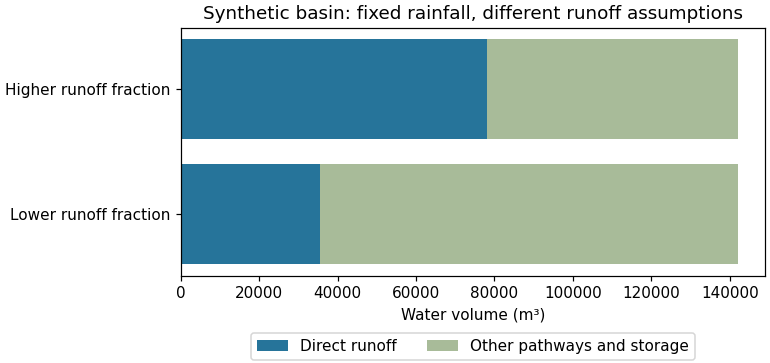

At f=0.25, direct runoff is 35,500 m³.
At f=0.55, direct runoff is 78,100 m³.


In [2]:
runoff_fraction = np.array([0.25, 0.55])
runoff_m3 = runoff_fraction * volume_m3
remainder_m3 = volume_m3 - runoff_m3

fig, ax = plt.subplots(figsize=(7, 3.3), layout="constrained")
labels = ["Lower runoff fraction", "Higher runoff fraction"]
ax.barh(labels, runoff_m3, label="Direct runoff", color="#26749a")
ax.barh(labels, remainder_m3, left=runoff_m3, label="Other pathways and storage", color="#a8bb99")
ax.set(xlabel="Water volume (m³)", title="Synthetic basin: fixed rainfall, different runoff assumptions")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=2)
plt.show()
for fraction, runoff in zip(runoff_fraction, runoff_m3):
    print(f"At f={fraction:.2f}, direct runoff is {runoff:,.0f} m³.")
np.testing.assert_allclose(runoff_m3 + remainder_m3, volume_m3)

## Scenario 4 · The heaviest interval goes missing

The second interval in the first cell drops out. Keep its value missing. Report the volume represented by the valid samples and the area-time coverage. A simple count of filled entries would weight a small cell the same as a large one.

For a sensitivity exercise, fill the gap with a low case of 10 mm/h and a high case of 30 mm/h. The resulting range is conditional on those two choices. You would need local observations or a validated error model to assign probabilities.

In [3]:
incomplete = rain_mm_h.copy()
incomplete[1, 0] = np.nan
partial_volume_m3, coverage = rainfall_volume(incomplete, interval_h, area_km2)
print(f"Volume from available samples: {partial_volume_m3:,.0f} m³")
print(f"Area-time coverage: {coverage:.0%}")

for replacement_mm_h in (10.0, 30.0):
    assumed_complete = incomplete.copy()
    assumed_complete[1, 0] = replacement_mm_h
    scenario_volume, scenario_coverage = rainfall_volume(assumed_complete, interval_h, area_km2)
    print(f"Gap set to {replacement_mm_h:.0f} mm/h: {scenario_volume:,.0f} m³")
    assert scenario_coverage == 1.0
assert np.isclose(partial_volume_m3, 122000)
assert np.isclose(coverage, 0.95)

Volume from available samples: 122,000 m³
Area-time coverage: 95%
Gap set to 10 mm/h: 132,000 m³
Gap set to 30 mm/h: 152,000 m³


## Submit a basin water budget

Compare the 14.2 mm weighted depth with the unweighted mean of the three cell depths. Explain the difference using the cell areas. Move the missing sample to the largest cell and repeat the coverage calculation. Report the two quantities a planning team would need to distinguish total water volume from when the largest flow reaches a crossing.